# Part B: Flow Matching from Scratch!
Student notebook: implement the marked exercises using [the assignment](partb.html).


**Conventions:** MNIST pixels are in $[0,1]$. Flow time goes from Gaussian noise
at 0 to data at 1. Predict velocity $x_1-x_0$, not noise. Part B uses
$v_u+\gamma(v_c-v_u)$ with $\gamma=5$; this is different from Part A's guidance convention.

## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [ ]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'partb'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('UEsDBBQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAY29sYWJfc2V0dXAucHm1V11T3DYUfd9foZIH2YkRENI23Yk7QwlJmBSyA6QvDOPR2nd3VWzJleSFLcN/75VkG8MCaTPTfVivdaVzv8/VbmxsHFxD3lgoyHRFpLIwVeqSGLBNTfjMgibG8rmQc2IXQExT10pbMm1kUQIpVc7LcsU2NjZGovKS8CjFlFVgecEt7yTKjGZaVaTmdoHydieZ4Gu3xTTTWqscjOlXVmY0yjSgEdri869GaLQ1JecXo9GogBkREmVlmVXCGDQzuuISvYnHI4IfNOwwyMlMaGMT54UkDgchCSctMlGyXJGZ0ugSL1BBzfNLPgeD+7kl+YLLORTeTwc7L9WUl2TNLi8Us3VBsMZ9NBcGyEkjrajgQGulIzrplF2BBtLUGDU0QUhULgxpI8LISWurS8S+KvkU04Q+K0loD//Ih04BHQN0VTdSukz67I4JfUUTQtmfSshozeI49phtxpx9eJKZGnIxE6BNl77TbuUUrD/R5iHFBHkAjGkbzMSddm6FFDFhoTJRfBcbq1djskRw9CldLyTWiqIWL+4PwnUO9WO1x9rQHiv7QWHN+oDf6ThWEnoQzFu7TjDqTkTQ9m4JW8OZPnQ3cv7E485jxusaZNFZ98pLu4pwx9t9g1rAPGjpX1+QQ5mXTQEYBC6NsGIJpAAHCDIXWBsRsDkjVl2CFH+jUXHiQRupoQz14r3HH5UqmhIM88ChnjOtlDXpjeQVYBJLYSPKaHy+feET5Jadd9htrD1960+H0klvbvtcBnHS9weeeiTsnTgrhLFaTBuLMcRcr+ccYxMguwgPDR6TXGGjyOYuS4N6crs7ReN7HeALKdh+3u64+E8F9T1FVXOkLXew1kJifFvicQ3X81Zvruu8vvnawmhb7o4EWb6A/DJzHBudu9yA52o+xQTQzYomtBY1frcUiL82N1ERWJq8bDEv2grsnRByyUvhGAZxER+TsdanqvTsEwL4RJtKuPpfW9ThP2xPXCM/pATNG69T7IP2i7+Ti9uscVewWH1VXQL2VIITzxMv7uelBl6sNh9OinZIjJ9n42c59xV9juWVzCH5BteH8dbIboLPuZCMnC2gm5NDi68EzsWpmwyNwQDSuB2p2HQzMW80YDA1zsxuxA75KP3ASwNtVbhmTd0gZ/lV0RaUry6/GCmsXLkUWkmGZqEG3pTYIPunO2+3s/29/U8H2fvDE5ogVUQOaosyf5rG8QCLVZeF0M4kkMhlZ7qBBK6RXzJ16d/C3ieUffqQffpydBCUeLwtumjmbqrNeO5UPXc6mDo5+XI0OQsW3wPCfq1qm0E1haJARPOv4M5O9g6PH0HDCSDcnP4GyORw8jB4nTnICnHfAI9l764HXpDPAHWoNGrI/tf3e5uu7LEBkGZw3uh8seW/lyLMxmGDINHx3LIeLUz29IZW3Nalco1Ox/TXdJf9nLx7gwQ1wZJTV37tF/aa3g7b2xVbmlL34PQ+obc3hnA1im6oH5LIThXSDYKl6Rv24w7bRQWDnG4umqkXbrPdn1BZQkFIVRuvfZu9Td7t0Ns7hnriIjngzxCNtYUQmOGk98ssbwrOhMn4kovSkfaQRB/jnlMoIXe30o+Tr4TnOb5qjliOjAMV4O/PfD5H/u8usn2vu/Z1wFiLtUkHFszBYu6XIofMyUBbLIBoOx7OKlSII8kfZe4ykNA/TvaOyEfxGy5rR8tREFqFMcoqqJRebb1++XJ3O9mJ70FNVmdON54LNmRZOxOyLKGDeHUbwttw2z24391fjEAAeMI/+8p+omA6QxyL7uEb3ti8QjJDyra7r0lk4doS7ARV4P8bLt3dyd0n8CICZdwFMtzOgurRP1BLAQIUAxQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAAAAAAAAAAACAAQAAAABjb2xhYl9zZXR1cC5weVBLBQYAAAAAAQABADwAAACMBQAAAAA=')
assert hashlib.sha256(_support).hexdigest() == 'ba2fae2d7267a416d94cd581fd0ac5eadf93d641618063a782d0dffdc36d31cd', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

GPU: Tesla T4 VRAM GiB: 14.6
PyTorch: 2.11.0+cu130 torchvision: 0.26.0+cu130
Local cache: /content/cs180-hw3/.cache
Setup complete. Continue with the notebook below.


## Setup environment

In [ ]:
# Install requirements-partb.txt in the active environment before running.
# No automatic package changes to an existing GPU environment.
import sys
assert sys.version_info >= (3,9), 'Use Python 3.9 or newer.'

In [ ]:
import os, json, time, random
from pathlib import Path
from typing import Optional
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

SEED = 180
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
GROUP = os.environ.get('PARTB_GROUP','all')
assert GROUP in ('all','denoise','time','class','no_scheduler')
OUT = Path('results/partb') / GROUP
OUT.mkdir(parents=True, exist_ok=True)
metrics = {'seed':SEED,'group':GROUP,'torch':torch.__version__,
           'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
           'visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES'),
           'precision':'float32 with TF32 convolution/matmul enabled'}
print(metrics)
train_dataset = MNIST('data', train=True, download=True, transform=ToTensor())
test_dataset = MNIST('data', train=False, download=True, transform=ToTensor())
assert len(train_dataset)==60000 and len(test_dataset)==10000

def show_grid(images, title, filename, nrow=10):
    images = images.detach().float().cpu()
    grid = make_grid(images.clamp(0, 1), nrow=nrow, padding=2)
    fig, ax = plt.subplots(figsize=(12, max(2, len(images)/nrow*1.15)))
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


def loss_plot(losses, name):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(losses, alpha=.4, linewidth=.5)
    window = min(100, len(losses))
    smooth = torch.tensor(losses).unfold(0, window, 1).mean(1)
    ax.plot(range(window-1, len(losses)), smooth, linewidth=1)
    ax.set(xlabel='Optimizer step', ylabel='Mean squared error', title=name)
    fig.tight_layout(); fig.savefig(OUT / (name+'_loss.png'), dpi=120)
    plt.show(); plt.close(fig)


def make_loader(batch_size, seed=180):
    # Decode/normalize once; augmentation noise is still drawn fresh in each step.
    dataset = torch.utils.data.TensorDataset(train_dataset.data[:, None].float()/255,
                                             train_dataset.targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      pin_memory=device.type == 'cuda',
                      generator=torch.Generator().manual_seed(seed))

{'seed': 180, 'group': 'all', 'torch': '2.11.0+cu130', 'device': 'cuda', 'gpu': 'Tesla T4', 'visible_devices': None, 'precision': 'float32 with TF32 convolution/matmul enabled'}


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 490kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.34MB/s]


## Neural Network Resources

In this part, you will build and train a [UNet](https://arxiv.org/abs/1505.04597), which is more complex than the MLP you implemented in the NeRF project.  We provide all class definitions you may need (but feel free to add or modify them as necessary).  

Instead of asking ChatGPT to write everything for you, please consult the following resources when you get stuck — they will help you understand how and why things work under the hood.

- PyTorch Documentation — [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and [`AvgPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).
- PyTorch Documentation - [`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), the dataset we gonna use, and [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html), the off-the-shell dataloader we can directly use.
- PyTorch [tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) on how to train a classifier on CIFAR10 dataset. The structure of your training code will be very similar to this one.

# Part 1: Training a Single-step Denoising UNet


# Part 1.1: Implementing the UNet

## Implementing Simple and Composed Ops

In [ ]:

class Conv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 1, 1),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class DownConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 2, 1),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class UpConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(in_channels, out_channels, 4, 2, 1),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class Flatten(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.AvgPool2d(7),
            nn.GELU()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class Unflatten(nn.Module):
    def __init__(self, in_channels: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(in_channels, in_channels, 7, 7, 0),
            nn.BatchNorm2d(in_channels),
            nn.GELU()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Sequential(
            Conv(in_channels, out_channels),
            Conv(out_channels, out_channels)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class DownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Sequential(
            DownConv(in_channels, out_channels),
            ConvBlock(out_channels, out_channels)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class UpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Sequential(
            UpConv(in_channels, out_channels),
            ConvBlock(out_channels, out_channels)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

## Implementing Unconditional UNet

In [ ]:

class UnconditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int,
    ):
        super().__init__()

        D = num_hiddens

        # Encoder
        self.conv_in = ConvBlock(in_channels, D)
        self.down1 = DownBlock(D, D)
        self.down2 = DownBlock(D, 2 * D)

        # Bottleneck
        self.flatten = Flatten()
        self.unflatten = Unflatten(2 * D)

        # Decoder
        self.up1 = UpBlock(4 * D, D)
        self.up2 = UpBlock(2 * D, D)

        # Output
        self.conv_out = ConvBlock(2 * D, D)
        self.final = nn.Conv2d(D, in_channels, 3, 1, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), \
            "Expect input shape to be (28, 28)."

        # Encoder: save skip connections
        x0 = self.conv_in(x)     # (N, D, 28, 28)
        x1 = self.down1(x0)      # (N, D, 14, 14)
        x2 = self.down2(x1)      # (N, 2D, 7, 7)

        # Bottleneck
        x = self.flatten(x2)     # (N, 2D, 1, 1)
        x = self.unflatten(x)    # (N, 2D, 7, 7)

        # Decoder with skip connections
        x = torch.cat([x, x2], dim=1)
        x = self.up1(x)          # (N, D, 14, 14)

        x = torch.cat([x, x1], dim=1)
        x = self.up2(x)          # (N, D, 28, 28)

        x = torch.cat([x, x0], dim=1)
        x = self.conv_out(x)     # (N, D, 28, 28)

        return self.final(x)     # (N, 1, 28, 28)


In [ ]:

# Sanity test for our UNet architecture

model = UnconditionalUNet(
    in_channels=1,
    num_hiddens=128
).to(device)

x = torch.randn(4, 1, 28, 28).to(device)

y = model(x)

print("Input shape:", x.shape)
print("Output shape:", y.shape)
print("Parameters:", sum(p.numel() for p in model.parameters()))

assert y.shape == x.shape
assert torch.isfinite(y).all()

print("UNet test passed!")


Input shape: torch.Size([4, 1, 28, 28])
Output shape: torch.Size([4, 1, 28, 28])
Parameters: 7891073
UNet test passed!


# Part 1.2: Using the UNet to Train a Denoiser

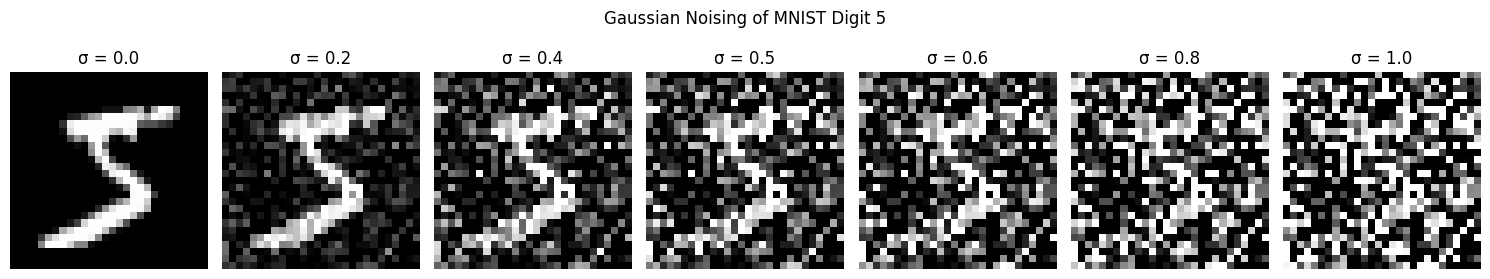

In [ ]:
# Visualize images at different noisy level
# ===== your code here! ====

# Select an MNIST digit
clean_image, label = train_dataset[0]

# Required noise levels
sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]

# Sample noise once for consistent comparisons
generator = torch.Generator().manual_seed(180)
noise = torch.randn(clean_image.shape, generator=generator)

fig, axes = plt.subplots(1, len(sigmas), figsize=(15, 3))

for ax, sigma in zip(axes, sigmas):
    # Add Gaussian noise: z = x + sigma * epsilon
    noisy_image = clean_image + sigma * noise

    # Clamp only for visualization
    ax.imshow(noisy_image.squeeze().clamp(0, 1), cmap="gray",
              vmin=0, vmax=1)
    ax.set_title(f"σ = {sigma}")
    ax.axis("off")

fig.suptitle(f"Gaussian Noising of MNIST Digit {label}")
plt.tight_layout()
plt.savefig(OUT / "part1_2_noising.png", dpi=150,
            bbox_inches="tight")
plt.show()
plt.close(fig)

# ===== end of code ====

## Part 1.2.1: Training

For this part, we provide some structure code for training. It is very basic, so feel free to change them or add your code. In later section we won't provide any training or visualization structure code.

In [ ]:
# Complete the recommended denoising hyperparameters from Section 1.2.1.

batch_size = 256
learning_rate = 1e-4
noise_level = 0.5
hidden_dim = 128
num_epochs = 5


In [ ]:
# MNIST train_dataset/test_dataset were loaded in setup.
# Build shuffled training and non-shuffled test DataLoaders.

train_loader = make_loader(batch_size=batch_size)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))

Training batches: 235
Test batches: 40


In [ ]:
# Define your model, optimizer, and loss
# ===== your code here! ====

model = UnconditionalUNet(
    in_channels=1,
    num_hiddens=hidden_dim
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

criterion = nn.MSELoss()

print("Training on:", device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

# ===== end of code ====

Training on: cuda
Parameters: 7891073


Epoch 1/5 | Average loss: 0.020700


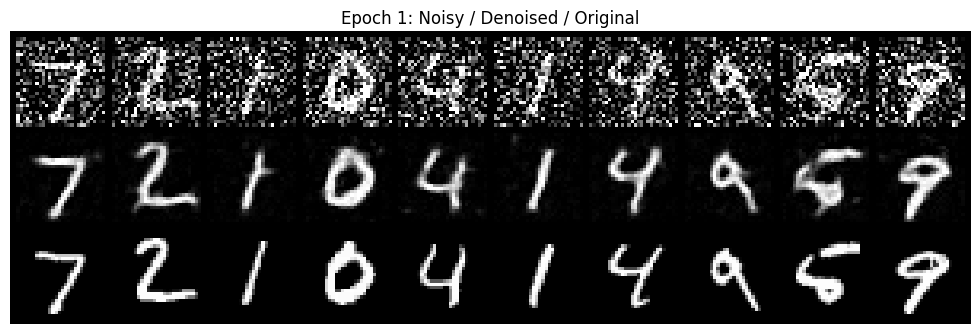

Epoch 2/5 | Average loss: 0.011163


Epoch 3/5 | Average loss: 0.009465


Epoch 4/5 | Average loss: 0.008659


Epoch 5/5 | Average loss: 0.008242


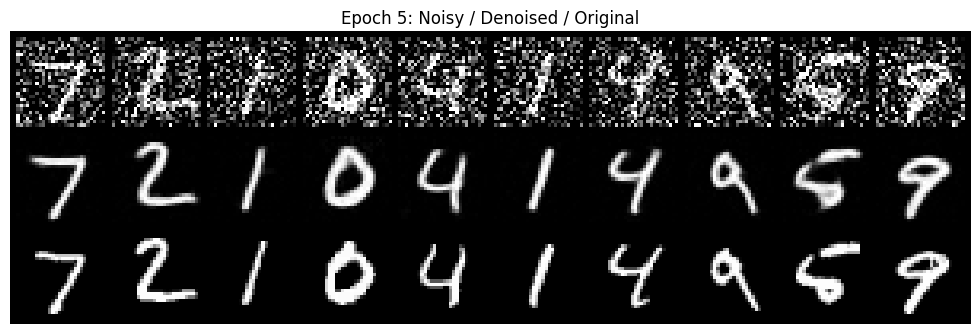

Training complete!


In [ ]:
# The training loops

from tqdm.auto import tqdm

# Fixed test examples for comparing epochs fairly
fixed_clean = next(iter(test_loader))[0][:10].to(device)

# Use the same noisy test inputs after epochs 1 and 5
test_gen = torch.Generator().manual_seed(180)
fixed_noise = torch.randn(
    fixed_clean.shape, generator=test_gen
).to(device)

fixed_noisy = fixed_clean + noise_level * fixed_noise

train_losses = []

for epoch in range(num_epochs):
    model.train()
    epoch_losses = []

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{num_epochs}"
    )

    for images, _ in progress:
        images = images.to(device)

        # Generate fresh Gaussian noise every batch
        noise = torch.randn_like(images)
        noisy_images = images + noise_level * noise

        # Predict the clean images
        outputs = model(noisy_images)

        # MSE against original clean images
        loss = criterion(outputs, images)

        # Gradient descent
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())
        epoch_losses.append(loss.item())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    avg_loss = sum(epoch_losses) / len(epoch_losses)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"| Average loss: {avg_loss:.6f}"
    )

    # Save required visualizations at epochs 1 and 5
    if (epoch + 1) in [1, 5]:
        model.eval()

        with torch.no_grad():
            denoised = model(fixed_noisy)

        # Three rows:
        # Row 1: Noisy inputs
        # Row 2: Denoised predictions
        # Row 3: Clean ground truth
        comparison = torch.cat(
            [fixed_noisy, denoised, fixed_clean],
            dim=0
        )

        show_grid(
            comparison,
            title=(
                f"Epoch {epoch + 1}: "
                "Noisy / Denoised / Original"
            ),
            filename=f"denoiser_epoch_{epoch + 1}.png",
            nrow=10
        )

        # Save model checkpoint
        torch.save(
            model.state_dict(),
            OUT / f"denoiser_epoch_{epoch + 1}.pt"
        )

print("Training complete!")

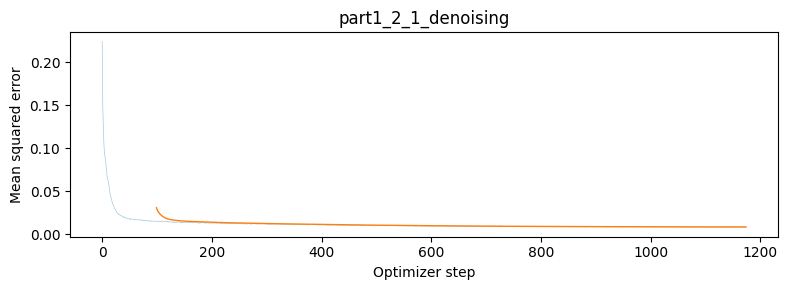

In [ ]:
# Visualize your training curve
# ===== your code here! ====

loss_plot(
    train_losses,
    "part1_2_1_denoising"
)
# ===== end of code ====

## Part 1.2.2: Out-of-Distribution Testing

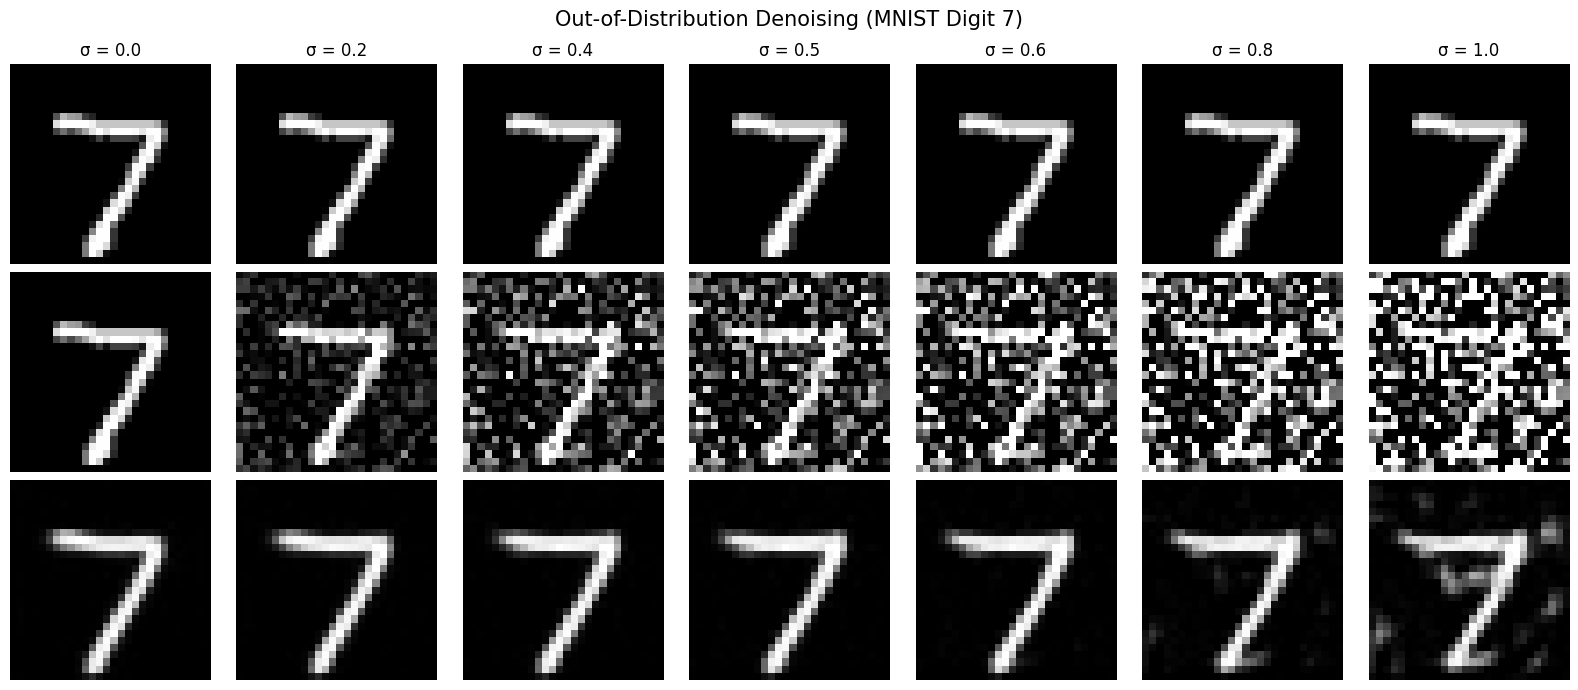

Sigma 0.0: MSE = 0.002119
Sigma 0.2: MSE = 0.003006
Sigma 0.4: MSE = 0.004797
Sigma 0.5: MSE = 0.005815
Sigma 0.6: MSE = 0.006834
Sigma 0.8: MSE = 0.009830
Sigma 1.0: MSE = 0.021645


In [ ]:
# Visualize OOD testing
# ===== your code here! ====

# Part 1.2.2: Out-of-Distribution Testing

model.eval()

sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]

# Select one image from the held-out MNIST test set
clean_image, label = test_dataset[0]
clean_image = clean_image.unsqueeze(0).to(device)

# Reuse the same Gaussian noise for all sigma values
generator = torch.Generator().manual_seed(180)
noise = torch.randn(
    clean_image.shape, generator=generator
).to(device)

fig, axes = plt.subplots(3, len(sigmas), figsize=(16, 7))

mse_values = []

with torch.no_grad():
    for i, sigma in enumerate(sigmas):

        noisy_image = clean_image + sigma * noise

        # Denoise using our trained UNet
        denoised_image = model(noisy_image)

        mse = F.mse_loss(denoised_image, clean_image).item()
        mse_values.append(mse)

        # Original image
        axes[0, i].imshow(
            clean_image[0, 0].cpu(),
            cmap="gray", vmin=0, vmax=1
        )

        # Noisy input
        axes[1, i].imshow(
            noisy_image[0, 0].clamp(0, 1).cpu(),
            cmap="gray", vmin=0, vmax=1
        )

        # Denoised output
        axes[2, i].imshow(
            denoised_image[0, 0].clamp(0, 1).cpu(),
            cmap="gray", vmin=0, vmax=1
        )

        axes[0, i].set_title(f"σ = {sigma}")

        for row in range(3):
            axes[row, i].axis("off")

for row, name in enumerate(["Original", "Noisy", "Denoised"]):
    axes[row, 0].set_ylabel(
        name, fontsize=12, rotation=90, labelpad=12
    )
    axes[row, 0].yaxis.set_label_coords(-0.12, 0.5)

fig.suptitle(
    f"Out-of-Distribution Denoising (MNIST Digit {label})",
    fontsize=15
)

plt.tight_layout()
plt.savefig(
    OUT / "part1_2_2_ood_testing.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Print reconstruction errors
for sigma, mse in zip(sigmas, mse_values):
    print(f"Sigma {sigma:.1f}: MSE = {mse:.6f}")

# ===== end of code ====

## Part 1.2.3 Denoising Pure Noise

Epoch 1/5 | Average loss: 0.078155


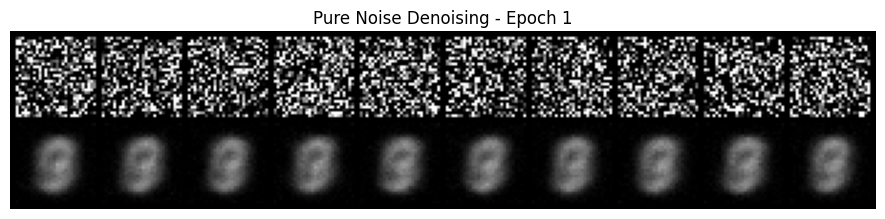

Epoch 2/5 | Average loss: 0.067562


Epoch 3/5 | Average loss: 0.067459


Epoch 4/5 | Average loss: 0.067407


Epoch 5/5 | Average loss: 0.067407


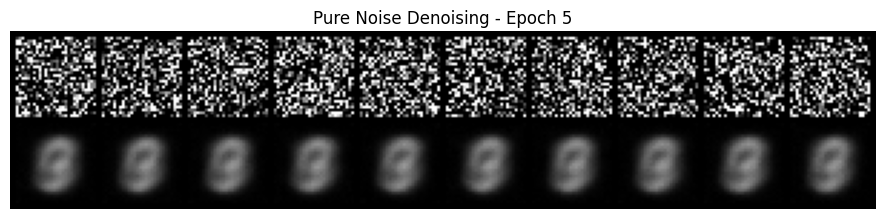

Pure-noise training complete!


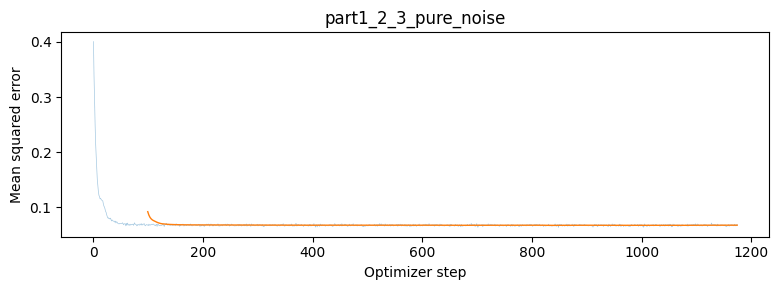

In [ ]:
# Section 1.2.3: train a fresh D=128 UNet for 5 epochs, Adam lr=1e-4,
# batch size 256. Input is independent Gaussian noise, target is a clean digit.
# Plot losses, show held-out results at epochs 1 and 5, and explain averaging.

# Part 1.2.3: Denoising Pure Noise

from tqdm.auto import tqdm

# Hyperparameters
pure_batch_size = 256
pure_learning_rate = 1e-4
pure_hidden_dim = 128
pure_num_epochs = 5

# Training loader
pure_train_loader = make_loader(
    batch_size=pure_batch_size,
    seed=181
)

# Fresh UNet, trained from scratch
pure_noise_model = UnconditionalUNet(
    in_channels=1,
    num_hiddens=pure_hidden_dim
).to(device)

pure_optimizer = torch.optim.Adam(
    pure_noise_model.parameters(),
    lr=pure_learning_rate
)

pure_criterion = nn.MSELoss()

# Fixed random inputs for fair epoch comparisons
generator = torch.Generator().manual_seed(180)
fixed_pure_noise = torch.randn(
    (10, 1, 28, 28),
    generator=generator
).to(device)

pure_noise_losses = []

# Train
for epoch in range(pure_num_epochs):
    pure_noise_model.train()
    epoch_losses = []

    progress = tqdm(
        pure_train_loader,
        desc=f"Pure Noise Epoch {epoch+1}/{pure_num_epochs}"
    )

    for images, _ in progress:
        images = images.to(device)

        # Input is entirely random Gaussian noise
        # Independent of the target digit
        noise_inputs = torch.randn_like(images)

        # Predict clean digit from pure noise
        outputs = pure_noise_model(noise_inputs)

        # MSE against original MNIST digits
        loss = pure_criterion(outputs, images)

        pure_optimizer.zero_grad()
        loss.backward()
        pure_optimizer.step()

        pure_noise_losses.append(loss.item())
        epoch_losses.append(loss.item())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    avg_loss = sum(epoch_losses) / len(epoch_losses)

    print(
        f"Epoch {epoch+1}/{pure_num_epochs} "
        f"| Average loss: {avg_loss:.6f}"
    )

    # Required output after epochs 1 and 5
    if (epoch + 1) in [1, 5]:
        pure_noise_model.eval()

        with torch.no_grad():
            generated = pure_noise_model(fixed_pure_noise)

        # Top row: random noise inputs
        # Bottom row: predicted images
        comparison = torch.cat(
            [fixed_pure_noise, generated],
            dim=0
        )

        show_grid(
            comparison,
            title=f"Pure Noise Denoising - Epoch {epoch+1}",
            filename=f"pure_noise_epoch_{epoch+1}.png",
            nrow=10
        )

        # Save checkpoint
        torch.save(
            pure_noise_model.state_dict(),
            OUT / f"pure_noise_epoch_{epoch+1}.pt"
        )

print("Pure-noise training complete!")

# Plot training loss
loss_plot(
    pure_noise_losses,
    "part1_2_3_pure_noise"
)


# Part 2: Flow Matching

# Part 2.1: Implementing a Time-conditioned UNet

In [ ]:

class FCBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(in_channels, out_channels),
            nn.GELU(),
            nn.Linear(out_channels, out_channels)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)



class TimeConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()

        D = num_hiddens

        # Encoder (same as our previous UNet)
        self.conv_in = ConvBlock(in_channels, D)
        self.down1 = DownBlock(D, D)
        self.down2 = DownBlock(D, 2 * D)

        # Bottleneck
        self.flatten = Flatten()
        self.unflatten = Unflatten(2 * D)

        # Decoder
        self.up1 = UpBlock(4 * D, D)
        self.up2 = UpBlock(2 * D, D)

        # Output
        self.conv_out = ConvBlock(2 * D, D)
        self.final = nn.Conv2d(D, in_channels, 3, 1, 1)

        # Time-conditioning embeddings
        self.fc1_t = FCBlock(1, 2 * D)
        self.fc2_t = FCBlock(1, D)

    def forward(
        self,
        x: torch.Tensor,
        t: torch.Tensor,
    ) -> torch.Tensor:

        assert x.shape[-2:] == (28, 28), \
            "Expect input shape to be (28, 28)."

        N = x.shape[0]

        # t starts as (N,), reshape to (N, 1)
        t = t.reshape(N, 1).to(
            device=x.device, dtype=x.dtype
        )

        # Time embeddings, broadcast over H and W
        t1 = self.fc1_t(t).reshape(N, -1, 1, 1)
        t2 = self.fc2_t(t).reshape(N, -1, 1, 1)

        # Encoder
        x0 = self.conv_in(x)    # (N, D, 28, 28)
        x1 = self.down1(x0)     # (N, D, 14, 14)
        x2 = self.down2(x1)     # (N, 2D, 7, 7)

        # Bottleneck
        x = self.flatten(x2)    # (N, 2D, 1, 1)
        x = self.unflatten(x)   # (N, 2D, 7, 7)

        # Inject first time embedding
        x = x * t1

        # Decoder, first upsampling stage
        x = torch.cat([x, x2], dim=1)
        x = self.up1(x)         # (N, D, 14, 14)

        # Inject second time embedding
        x = x * t2

        # Decoder, second upsampling stage
        x = torch.cat([x, x1], dim=1)
        x = self.up2(x)         # (N, D, 28, 28)

        # Final skip connection and output
        x = torch.cat([x, x0], dim=1)
        x = self.conv_out(x)

        return self.final(x)    # (N, 1, 28, 28)


In [ ]:

# Part 2.1: Sanity test

time_unet = TimeConditionalUNet(
    in_channels=1,
    num_classes=10,
    num_hiddens=64
).to(device)

# Two random MNIST-sized images
x = torch.randn(2, 1, 28, 28).to(device)

# Different timesteps for each image
t = torch.tensor([0.25, 0.75]).to(device)

# Forward pass
y = time_unet(x, t)

print("Input shape:", x.shape)
print("Time shape:", t.shape)
print("Output shape:", y.shape)
print(
    "Parameters:",
    sum(p.numel() for p in time_unet.parameters())
)

# Check output shape and numerical validity
assert y.shape == x.shape
assert torch.isfinite(y).all()

# Check that backpropagation works
loss = y.square().mean()
loss.backward()

assert time_unet.fc1_t.net[0].weight.grad is not None
assert time_unet.fc2_t.net[0].weight.grad is not None

print("Time-conditioned UNet test passed!")


Input shape: torch.Size([2, 1, 28, 28])
Time shape: torch.Size([2])
Output shape: torch.Size([2, 1, 28, 28])
Parameters: 1996417
Time-conditioned UNet test passed!


## Implementing the Forward and Reverse Process for Time-conditioned Denoising




In [ ]:

def time_fm_forward(
    unet: TimeConditionalUNet,
    x_1: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    """
    Compute the flow-matching training loss.

    Args:
        unet: Time-conditioned UNet.
        x_1: Clean MNIST images, (N, C, H, W).
        num_ts: Number of sampling timesteps.

    Returns:
        Scalar flow-matching MSE loss.
    """
    unet.train()

    N = x_1.shape[0]

    # 1. Sample independent Gaussian noise
    x_0 = torch.randn_like(x_1)

    # 2. Sample random normalized times in [0, 1]
    t = torch.rand(N, device=x_1.device)

    # 3. Interpolate between noise and clean images
    t_expanded = t.view(N, 1, 1, 1)
    x_t = (1 - t_expanded) * x_0 + t_expanded * x_1

    # 4. Ground-truth velocity
    v_true = x_1 - x_0

    # 5. Predict velocity using time-conditioned UNet
    v_pred = unet(x_t, t)

    # 6. Compute flow-matching loss
    loss = F.mse_loss(v_pred, v_true)

    return loss

In [ ]:

@torch.inference_mode()
def time_fm_sample(
    unet: TimeConditionalUNet,
    img_wh: tuple[int, int],
    num_ts: int,
    seed: int = 0,
) -> torch.Tensor:
    """
    Generate MNIST images from Gaussian noise
    using Euler integration.
    """
    unet.eval()

    device = next(unet.parameters()).device
    dtype = next(unet.parameters()).dtype

    N = 10
    H, W = img_wh

    # Reproducible random noise
    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    x = torch.randn(
        (N, 1, H, W),
        generator=generator,
        device=device,
        dtype=dtype
    )

    # Euler step size
    dt = 1.0 / num_ts

    # Integrate from t = 0 to t = 1
    for i in range(num_ts):
        t = torch.full(
            (N,),
            i / num_ts,
            device=device,
            dtype=dtype
        )

        # Predict velocity at current state and time
        v = unet(x, t)

        # Euler update
        x = x + dt * v

    return x


In [ ]:
class TimeConditionalFM(nn.Module):
    def __init__(
        self,
        unet: TimeConditionalUNet,
        num_ts: int = 50,
        img_hw: tuple[int, int] = (28, 28),
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.img_hw = img_hw


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) flow-matching loss.
        """
        return time_fm_forward(
            self.unet, x, self.num_ts
        )


    @torch.inference_mode()
    def sample(
        self,
        img_wh: tuple[int, int],
        seed: int = 0,
    ):
        return time_fm_sample(
            self.unet, img_wh, self.num_ts, seed
        )

In [ ]:

# Sanity tests: forward loss and Euler sampling

time_unet = TimeConditionalUNet(
    in_channels=1,
    num_classes=10,
    num_hiddens=64
).to(device)

fm_model = TimeConditionalFM(
    unet=time_unet,
    num_ts=50
).to(device)

# Test 1: Training loss
x = torch.rand(4, 1, 28, 28, device=device)

loss = fm_model(x)

print("Flow matching loss:", loss.item())
print("Loss shape:", loss.shape)

assert loss.ndim == 0
assert torch.isfinite(loss)

# Test 2: Gradients
loss.backward()

assert any(
    p.grad is not None for p in fm_model.parameters()
)

print("Backward pass successful!")

# Test 3: Sampling
# Use only 5 steps for quick testing
test_samples = time_fm_sample(
    unet=time_unet,
    img_wh=(28, 28),
    num_ts=5,
    seed=180
)

print("Sample shape:", test_samples.shape)

assert test_samples.shape == (10, 1, 28, 28)
assert torch.isfinite(test_samples).all()

print("All flow matching tests passed!")


Flow matching loss: 1.2709758281707764
Loss shape: torch.Size([])
Backward pass successful!
Sample shape: torch.Size([10, 1, 28, 28])
All flow matching tests passed!


# Part 2.2: Training the Time-conditioned UNet

Epoch 1/10 | Average loss: 0.166770 | LR: 0.010000


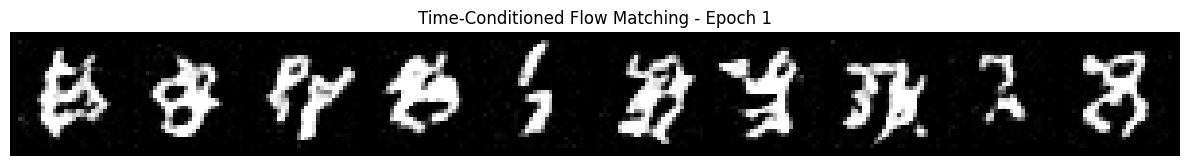

Epoch 2/10 | Average loss: 0.120362 | LR: 0.007943


Epoch 3/10 | Average loss: 0.109185 | LR: 0.006310


Epoch 4/10 | Average loss: 0.103052 | LR: 0.005012


Epoch 5/10 | Average loss: 0.099599 | LR: 0.003981


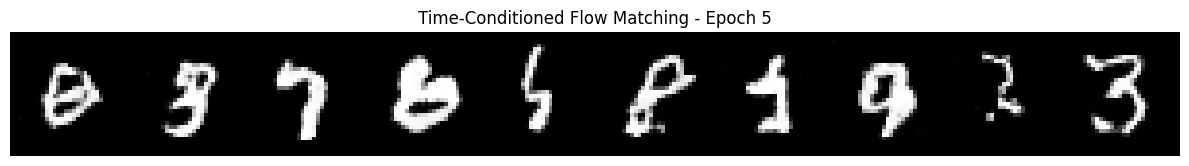

Epoch 6/10 | Average loss: 0.097249 | LR: 0.003162


Epoch 7/10 | Average loss: 0.095295 | LR: 0.002512


Epoch 8/10 | Average loss: 0.095049 | LR: 0.001995


Epoch 9/10 | Average loss: 0.093315 | LR: 0.001585


Epoch 10/10 | Average loss: 0.092108 | LR: 0.001259


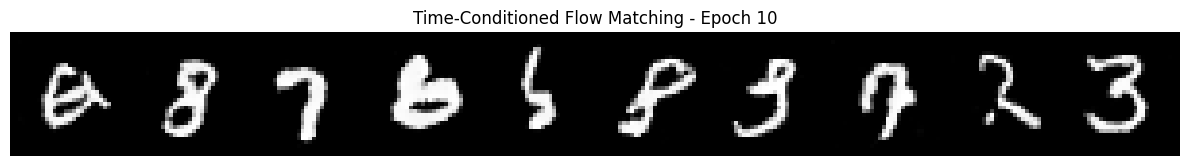

Time-conditioned flow matching training complete!


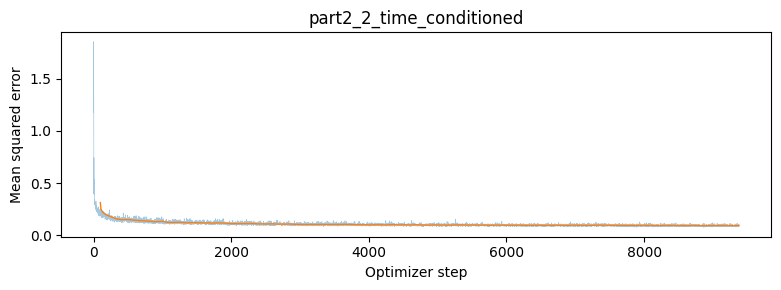

In [ ]:
# Feel free to use code from part 1.2.1
# as they should be very similar
# ===== your code here! ====

# Part 2.2: Train Time-Conditioned Flow Matching UNet

from tqdm.auto import tqdm

# Hyperparameters
time_batch_size = 64
time_hidden_dim = 64
time_num_epochs = 10
time_learning_rate = 1e-2
time_num_ts = 50

# Dataset
time_train_loader = make_loader(
    batch_size=time_batch_size,
    seed=180
)

# Fresh model
time_unet = TimeConditionalUNet(
    in_channels=1,
    num_classes=10,
    num_hiddens=time_hidden_dim
).to(device)

# Flow matching wrapper
time_fm = TimeConditionalFM(
    unet=time_unet,
    num_ts=time_num_ts
).to(device)

# Optimizer
time_optimizer = torch.optim.Adam(
    time_fm.parameters(),
    lr=time_learning_rate
)

# Exponential learning rate scheduler
time_scheduler = torch.optim.lr_scheduler.ExponentialLR(
    time_optimizer,
    gamma=0.1 ** (1 / time_num_epochs)
)

time_train_losses = []

# Training
for epoch in range(time_num_epochs):

    time_fm.train()
    epoch_losses = []

    progress = tqdm(
        time_train_loader,
        desc=f"Time FM Epoch {epoch+1}/{time_num_epochs}"
    )

    for images, _ in progress:

        images = images.to(device)

        # Compute flow matching loss
        loss = time_fm(images)

        # Gradient descent
        time_optimizer.zero_grad(set_to_none=True)
        loss.backward()
        time_optimizer.step()

        time_train_losses.append(loss.item())
        epoch_losses.append(loss.item())

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_loss = sum(epoch_losses) / len(epoch_losses)

    print(
        f"Epoch {epoch+1}/{time_num_epochs} "
        f"| Average loss: {avg_loss:.6f} "
        f"| LR: {time_optimizer.param_groups[0]['lr']:.6f}"
    )

    # Update learning rate after each epoch
    time_scheduler.step()

    # Save a recovery checkpoint every epoch
    torch.save(
        {
            "epoch": epoch + 1,
            "model": time_unet.state_dict(),
            "optimizer": time_optimizer.state_dict(),
            "scheduler": time_scheduler.state_dict(),
            "losses": time_train_losses
        },
        OUT / "time_fm_latest.pt"
    )

    # Save results at required epochs
    if (epoch + 1) in [1, 5, 10]:

        # Save model weights
        torch.save(
            time_unet.state_dict(),
            OUT / f"time_fm_epoch_{epoch+1}.pt"
        )

        # Generate digits using Euler sampling
        with torch.inference_mode():
            samples = time_fm.sample(
                img_wh=(28, 28),
                seed=180
            )

        # Save and display generated images
        show_grid(
            samples,
            title=f"Time-Conditioned Flow Matching - Epoch {epoch+1}",
            filename=f"time_fm_epoch_{epoch+1}.png",
            nrow=10
        )

print("Time-conditioned flow matching training complete!")

# Plot the loss curve
loss_plot(
    time_train_losses,
    "part2_2_time_conditioned"
)

# ===== end of code ====

# Part 2.3: Sampling from the Time-conditioned UNet

Epoch 1: Generated 10 images
Epoch 5: Generated 10 images
Epoch 10: Generated 10 images


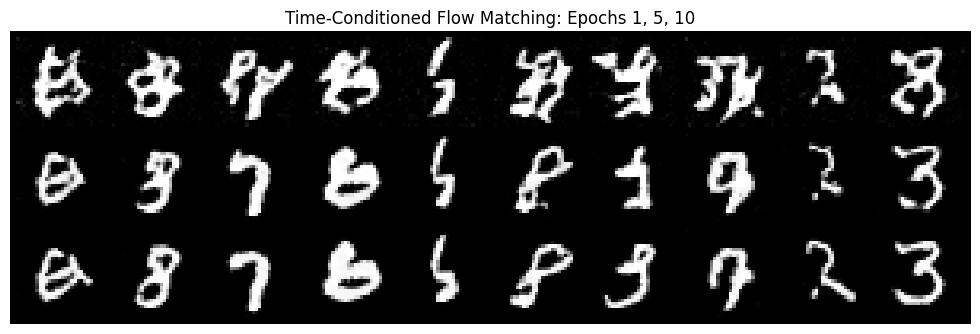

Part 2.3 sampling complete!


In [ ]:
# Sampling from the UNet
# ===== your code here! ====

# Part 2.3: Sampling from Time-Conditioned UNet

epochs_to_compare = [1, 5, 10]
all_samples = []

for epoch in epochs_to_compare:

    # Load the saved UNet checkpoint
    checkpoint_path = OUT / f"time_fm_epoch_{epoch}.pt"

    sample_unet = TimeConditionalUNet(
        in_channels=1,
        num_classes=10,
        num_hiddens=64
    ).to(device)

    sample_unet.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

    sample_unet.eval()

    # Create flow matching wrapper
    sample_fm = TimeConditionalFM(
        unet=sample_unet,
        num_ts=50
    ).to(device)

    # Generate 10 samples from fixed initial noise
    samples = sample_fm.sample(
        img_wh=(28, 28),
        seed=180
    )

    all_samples.append(samples.detach().cpu())

    print(f"Epoch {epoch}: Generated {len(samples)} images")


comparison = torch.cat(all_samples, dim=0)

show_grid(
    comparison,
    title="Time-Conditioned Flow Matching: Epochs 1, 5, 10",
    filename="part2_3_sampling_comparison.png",
    nrow=10
)

print("Part 2.3 sampling complete!")

# ===== end of code ====

# Part 2.4: Implementing a Class-conditioned UNet

In [ ]:

class ClassConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()

        D = num_hiddens
        self.num_classes = num_classes

        self.conv_in = ConvBlock(in_channels, D)
        self.down1 = DownBlock(D, D)
        self.down2 = DownBlock(D, 2 * D)

        self.flatten = Flatten()
        self.unflatten = Unflatten(2 * D)

        self.up1 = UpBlock(4 * D, D)
        self.up2 = UpBlock(2 * D, D)
        self.conv_out = ConvBlock(2 * D, D)
        self.final = nn.Conv2d(D, in_channels, 3, 1, 1)

        # conditioning
        self.fc1_t = FCBlock(1, 2 * D)
        self.fc2_t = FCBlock(1, D)

        self.fc1_c = FCBlock(num_classes, 2 * D)
        self.fc2_c = FCBlock(num_classes, D)

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:

        assert x.shape[-2:] == (28, 28), \
            "Expect input shape to be (28, 28)."

        N = x.shape[0]

        t = t.reshape(N, 1).to(
            device=x.device, dtype=x.dtype
        )

        # Convert digit labels to one-hot vectors
        c = F.one_hot(
            c.long(),
            num_classes=self.num_classes
        ).to(device=x.device, dtype=x.dtype)

        # Classifier-free guidance dropout
        if mask is not None:
            mask = mask.reshape(N, 1).to(
                device=x.device, dtype=x.dtype
            )
            c = c * mask

        # Conditioning embeddings
        t1 = self.fc1_t(t).reshape(N, -1, 1, 1)
        t2 = self.fc2_t(t).reshape(N, -1, 1, 1)

        c1 = self.fc1_c(c).reshape(N, -1, 1, 1)
        c2 = self.fc2_c(c).reshape(N, -1, 1, 1)

        x0 = self.conv_in(x)
        x1 = self.down1(x0)
        x2 = self.down2(x1)

        x = self.flatten(x2)
        x = self.unflatten(x)

        # Inject time and class conditioning
        x = c1 * x + t1

        # First decoder stage
        x = torch.cat([x, x2], dim=1)
        x = self.up1(x)

        # Second conditioning injection amd decoder stage
        x = c2 * x + t2

        x = torch.cat([x, x1], dim=1)
        x = self.up2(x)

        x = torch.cat([x, x0], dim=1)
        x = self.conv_out(x)

        return self.final(x)


In [ ]:

def class_fm_forward(
    unet: ClassConditionalUNet,
    x_1: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:
    """
    Class-conditioned flow matching training loss.
    """
    unet.train()

    N = x_1.shape[0]

    # 1. Sample Gaussian noise
    x_0 = torch.randn_like(x_1)

    # 2. Random normalized times
    t = torch.rand(
        N, device=x_1.device, dtype=x_1.dtype
    )

    # 3. Interpolate between noise and clean digits
    t_expanded = t.view(N, 1, 1, 1)
    x_t = (1 - t_expanded) * x_0 + t_expanded * x_1

    # 4. Target velocity
    v_true = x_1 - x_0

    # 5. Randomly drop class conditioning
    # True = retain class, False = remove class
    mask = (
        torch.rand(N, device=x_1.device) >= p_uncond
    )

    # 6. Predict class-conditioned velocity
    v_pred = unet(x_t, c, t, mask=mask)

    # 7. Flow matching MSE
    loss = F.mse_loss(v_pred, v_true)

    return loss

In [ ]:

@torch.inference_mode()
def class_fm_sample(
    unet: ClassConditionalUNet,
    c: torch.Tensor,
    img_wh: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0,
    seed: int = 0,
) -> tuple[torch.Tensor, torch.Tensor]:
    """
    Class-conditioned sampling with CFG.

    Returns:
        final_samples: (N, C, H, W)
        caches: (N, T_animation, C, H, W)
    """
    unet.eval()

    device = next(unet.parameters()).device
    dtype = next(unet.parameters()).dtype

    c = c.to(device=device, dtype=torch.long).reshape(-1)

    N = c.shape[0]
    H, W = img_wh

    # Reproducible initial noise
    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    x = torch.randn(
        (N, 1, H, W),
        generator=generator,
        device=device,
        dtype=dtype
    )

    dt = 1.0 / num_ts

    # Cache approximately 10 intermediate stages
    caches = [x.detach().cpu()]
    save_every = max(1, num_ts // 10)

    # Euler integration from noise to image
    for i in range(num_ts):

        t = torch.full(
            (N,),
            i / num_ts,
            device=device,
            dtype=dtype
        )

        # Conditional velocity
        v_cond = unet(x, c, t)

        # Unconditional velocity: mask out the class
        zero_mask = torch.zeros(N, device=device)
        v_uncond = unet(x, c, t, mask=zero_mask)

        # Classifier-free guidance
        v = v_uncond + guidance_scale * (
            v_cond - v_uncond
        )

        # Euler update
        x = x + dt * v

        # Save intermediate states for visualization
        if (i + 1) % save_every == 0 or i + 1 == num_ts:
            caches.append(x.detach().cpu())

    caches = torch.stack(caches, dim=1)

    return x, caches

In [ ]:
class ClassConditionalFM(nn.Module):
    def __init__(
        self,
        unet: ClassConditionalUNet,
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self.num_ts = num_ts
        self.p_uncond = p_uncond

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.

        Returns:
            (,) loss.
        """
        return class_fm_forward(
            self.unet, x, c, self.p_uncond, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_wh: tuple[int, int],
        guidance_scale: float = 5.0,
        seed: int = 0,
    ):
        return class_fm_sample(
            self.unet, c, img_wh, self.num_ts, guidance_scale, seed
        )

# Part 2.5 Training the Class-conditioned UNet

In [ ]:
# Train a fresh class-conditioned D=64 UNet for 10 epochs, batch size 64,
# Adam initial lr=1e-2, class dropout probability .1, exponential gamma=.1**(1/10).
# Save checkpoints at epochs 1,5,10. Then train an independent no-scheduler
# comparison; choose/document a constant learning rate and compare results.

# Part 2.5: Class-Conditioned Flow Matching Training

from tqdm.auto import tqdm

CLASS_BATCH_SIZE = 64
CLASS_HIDDEN_DIM = 64
CLASS_NUM_EPOCHS = 10
CLASS_NUM_TS = 300
CLASS_P_UNCOND = 0.1


def train_class_model(
    run_name,
    learning_rate,
    use_scheduler=True
):
    # Make both experiments reproducible
    torch.manual_seed(SEED)

    train_loader = make_loader(
        batch_size=CLASS_BATCH_SIZE,
        seed=SEED
    )

    # Fresh class-conditioned UNet
    unet = ClassConditionalUNet(
        in_channels=1,
        num_classes=10,
        num_hiddens=CLASS_HIDDEN_DIM
    ).to(device)

    fm = ClassConditionalFM(
        unet=unet,
        num_ts=CLASS_NUM_TS,
        p_uncond=CLASS_P_UNCOND
    ).to(device)

    optimizer = torch.optim.Adam(
        fm.parameters(),
        lr=learning_rate
    )

    scheduler = (
        torch.optim.lr_scheduler.ExponentialLR(
            optimizer,
            gamma=0.1 ** (1 / CLASS_NUM_EPOCHS)
        )
        if use_scheduler else None
    )

    losses = []
    epoch_losses = []
    start_epoch = 0

    latest_path = OUT / f"{run_name}_latest.pt"

    # Resume automatically if a checkpoint exists
    if latest_path.exists():
        checkpoint = torch.load(
            latest_path,
            map_location=device,
            weights_only=True
        )

        unet.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])

        if scheduler is not None:
            scheduler.load_state_dict(
                checkpoint["scheduler"]
            )

        losses = checkpoint["losses"]
        epoch_losses = checkpoint["epoch_losses"]
        start_epoch = checkpoint["epoch"]

        print(f"Resuming {run_name} after epoch {start_epoch}")

    # Training loop
    for epoch in range(start_epoch, CLASS_NUM_EPOCHS):
        fm.train()
        batch_losses = []

        progress = tqdm(
            train_loader,
            desc=f"{run_name}: Epoch {epoch+1}/10"
        )

        for images, labels in progress:

            images = images.to(device)
            labels = labels.to(device)

            # Flow-matching loss with class conditioning
            loss = fm(images, labels)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            losses.append(loss.item())
            batch_losses.append(loss.item())

            progress.set_postfix(
                loss=f"{loss.item():.4f}"
            )

        avg_loss = sum(batch_losses) / len(batch_losses)
        epoch_losses.append(avg_loss)

        print(
            f"Epoch {epoch+1}/10 "
            f"| Average loss: {avg_loss:.6f} "
            f"| LR: {optimizer.param_groups[0]['lr']:.6f}"
        )

        # Decay LR after the epoch
        if scheduler is not None:
            scheduler.step()

        # Save full recovery checkpoint
        torch.save(
            {
                "epoch": epoch + 1,
                "model": unet.state_dict(),
                "optimizer": optimizer.state_dict(),
                "scheduler": (
                    scheduler.state_dict()
                    if scheduler is not None else None
                ),
                "losses": losses,
                "epoch_losses": epoch_losses
            },
            latest_path
        )

        # Save required epoch checkpoints
        if (epoch + 1) in [1, 5, 10]:
            torch.save(
                unet.state_dict(),
                OUT / f"{run_name}_epoch_{epoch+1}.pt"
            )

    print(f"{run_name}: Training complete!")

    # Full training loss curve
    loss_plot(
        losses,
        f"{run_name}_training"
    )

    return unet, losses, epoch_losses


Epoch 1/10 | Average loss: 0.169802 | LR: 0.010000


Epoch 2/10 | Average loss: 0.116324 | LR: 0.007943


Epoch 3/10 | Average loss: 0.104457 | LR: 0.006310


Epoch 4/10 | Average loss: 0.096578 | LR: 0.005012


Epoch 5/10 | Average loss: 0.092938 | LR: 0.003981


Epoch 6/10 | Average loss: 0.090331 | LR: 0.003162


Epoch 7/10 | Average loss: 0.088071 | LR: 0.002512


Epoch 8/10 | Average loss: 0.086922 | LR: 0.001995


Epoch 9/10 | Average loss: 0.085613 | LR: 0.001585


Epoch 10/10 | Average loss: 0.084653 | LR: 0.001259
class_fm_scheduled: Training complete!


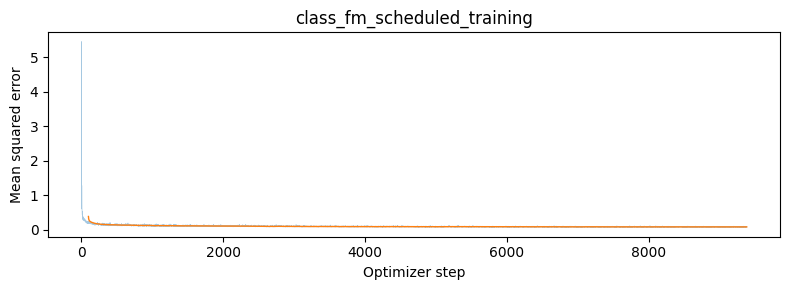

In [ ]:

# Experiment 1: Exponential learning-rate scheduler

class_unet_scheduled, class_losses_scheduled, class_epoch_losses_scheduled = (
    train_class_model(
        run_name="class_fm_scheduled",
        learning_rate=1e-2,
        use_scheduler=True
    )
)

Epoch 1/10 | Average loss: 0.142601 | LR: 0.002000


Epoch 2/10 | Average loss: 0.107764 | LR: 0.002000


Epoch 3/10 | Average loss: 0.100256 | LR: 0.002000


Epoch 4/10 | Average loss: 0.095197 | LR: 0.002000


Epoch 5/10 | Average loss: 0.092795 | LR: 0.002000


Epoch 6/10 | Average loss: 0.091364 | LR: 0.002000


Epoch 7/10 | Average loss: 0.089028 | LR: 0.002000


Epoch 8/10 | Average loss: 0.088008 | LR: 0.002000


Epoch 9/10 | Average loss: 0.086725 | LR: 0.002000


Epoch 10/10 | Average loss: 0.086311 | LR: 0.002000
class_fm_no_scheduler: Training complete!


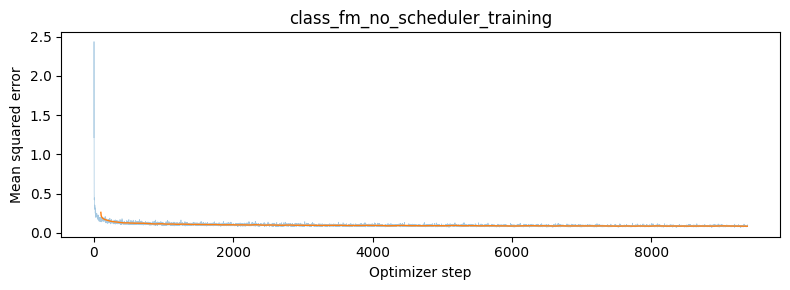

In [ ]:
# Experiment 2: No learning-rate scheduler

class_unet_no_scheduler, class_losses_no_scheduler, class_epoch_losses_no_scheduler = (
    train_class_model(
        run_name="class_fm_no_scheduler",
        learning_rate=2e-3,
        use_scheduler=False
    )
)

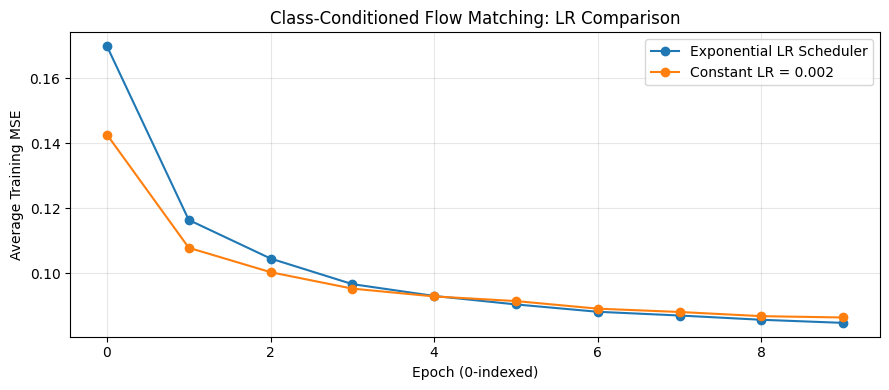

In [ ]:
# Compare scheduled vs no-scheduler training

plt.figure(figsize=(9, 4))

plt.plot(
    class_epoch_losses_scheduled,
    marker="o",
    label="Exponential LR Scheduler"
)

plt.plot(
    class_epoch_losses_no_scheduler,
    marker="o",
    label="Constant LR = 0.002"
)

plt.xlabel("Epoch (0-indexed)")
plt.ylabel("Average Training MSE")
plt.title("Class-Conditioned Flow Matching: LR Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUT / "class_fm_scheduler_comparison.png",
    dpi=150
)

plt.show()

# Part 2.6: Sampling from the Class-conditioned UNet

Class labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Total images per checkpoint: 40

Generating class_fm_scheduled, epoch 1...


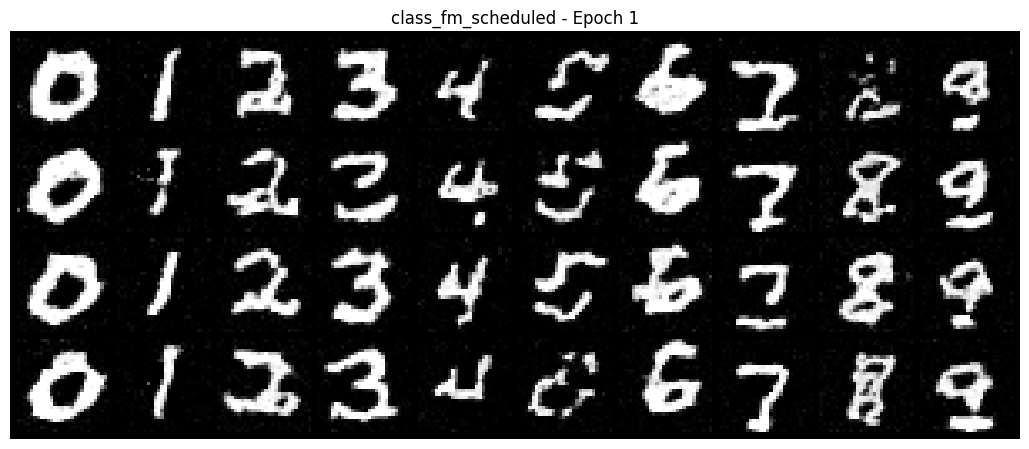

Saved: class_fm_scheduled_epoch_1_samples.png

Generating class_fm_scheduled, epoch 5...


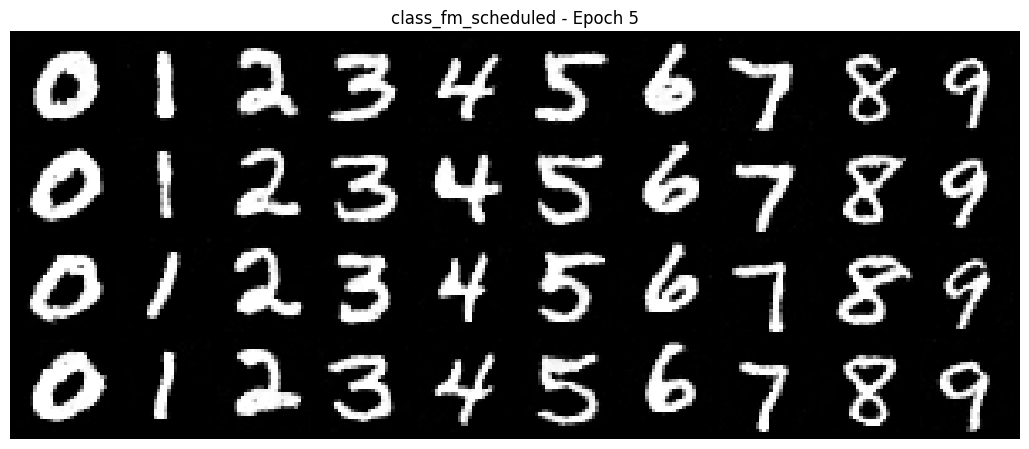

Saved: class_fm_scheduled_epoch_5_samples.png

Generating class_fm_scheduled, epoch 10...


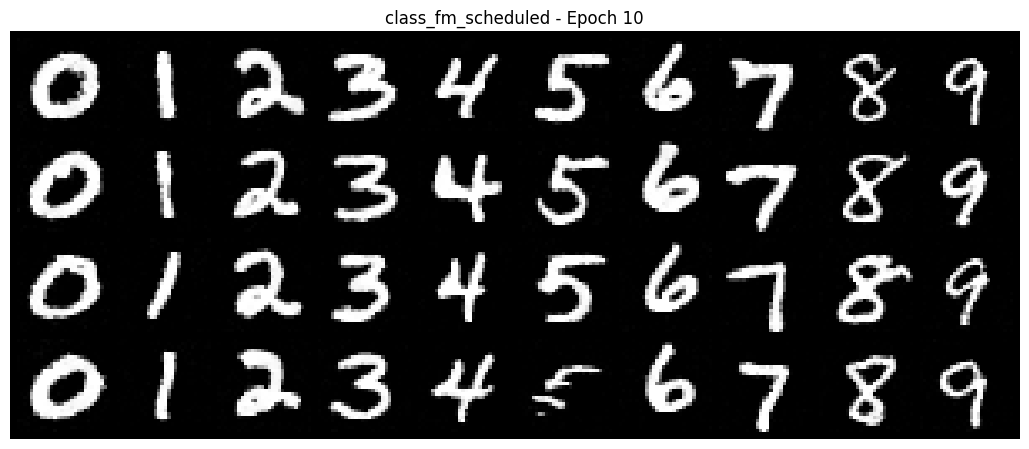

Saved: class_fm_scheduled_epoch_10_samples.png

Generating class_fm_no_scheduler, epoch 10...


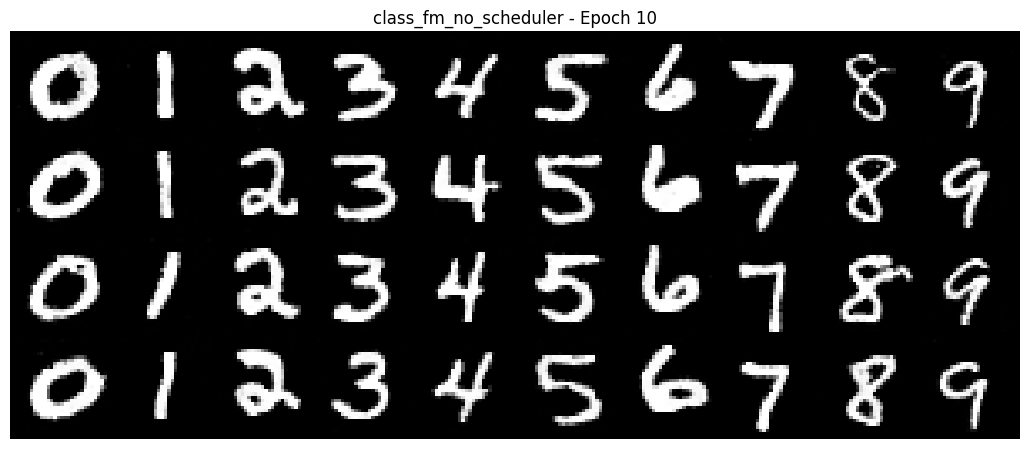

Saved: class_fm_no_scheduler_epoch_10_samples.png

Part 2.6 sampling complete!


In [ ]:
# At epochs 1,5,10, generate four instances of each digit (40 images),
# with 300 Euler steps and guidance scale 5.0. Keep seeds fixed for comparisons.
# Also visualize the no-scheduler model and describe the tradeoff.

# Four examples of each digit 0-9
# Rows = examples, columns = digit classes
classes = torch.arange(10).repeat(4).to(device)

print("Class labels:", classes.tolist())
print("Total images per checkpoint:", len(classes))

# Models to compare
experiments = [
    ("class_fm_scheduled", 1),
    ("class_fm_scheduled", 5),
    ("class_fm_scheduled", 10),
    ("class_fm_no_scheduler", 10),
]

results = {}

for run_name, epoch in experiments:

    print(f"\nGenerating {run_name}, epoch {epoch}...")

    # Create a fresh UNet with the same architecture
    sample_unet = ClassConditionalUNet(
        in_channels=1,
        num_classes=10,
        num_hiddens=64
    ).to(device)

    # Load trained weights
    checkpoint_path = (
        OUT / f"{run_name}_epoch_{epoch}.pt"
    )

    assert checkpoint_path.exists(), (
        f"Missing checkpoint: {checkpoint_path}"
    )

    sample_unet.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

    sample_unet.eval()

    # Wrap with flow-matching sampler
    sample_fm = ClassConditionalFM(
        unet=sample_unet,
        num_ts=300,
        p_uncond=0.1
    ).to(device)

    # Generate using CFG
    samples, caches = sample_fm.sample(
        c=classes,
        img_wh=(28, 28),
        guidance_scale=5.0,
        seed=180
    )

    # Store outputs
    results[(run_name, epoch)] = samples.detach().cpu()

    # Verify shape
    assert samples.shape == (40, 1, 28, 28)
    assert torch.isfinite(samples).all()

    # Save and display a 4x10 grid
    filename = f"{run_name}_epoch_{epoch}_samples.png"

    title = f"{run_name} - Epoch {epoch}"

    show_grid(
        samples,
        title=title,
        filename=filename,
        nrow=10
    )

    print(f"Saved: {filename}")

    # Free unused GPU memory
    del sample_unet, sample_fm, samples, caches
    if device.type == "cuda":
        torch.cuda.empty_cache()

print("\nPart 2.6 sampling complete!")


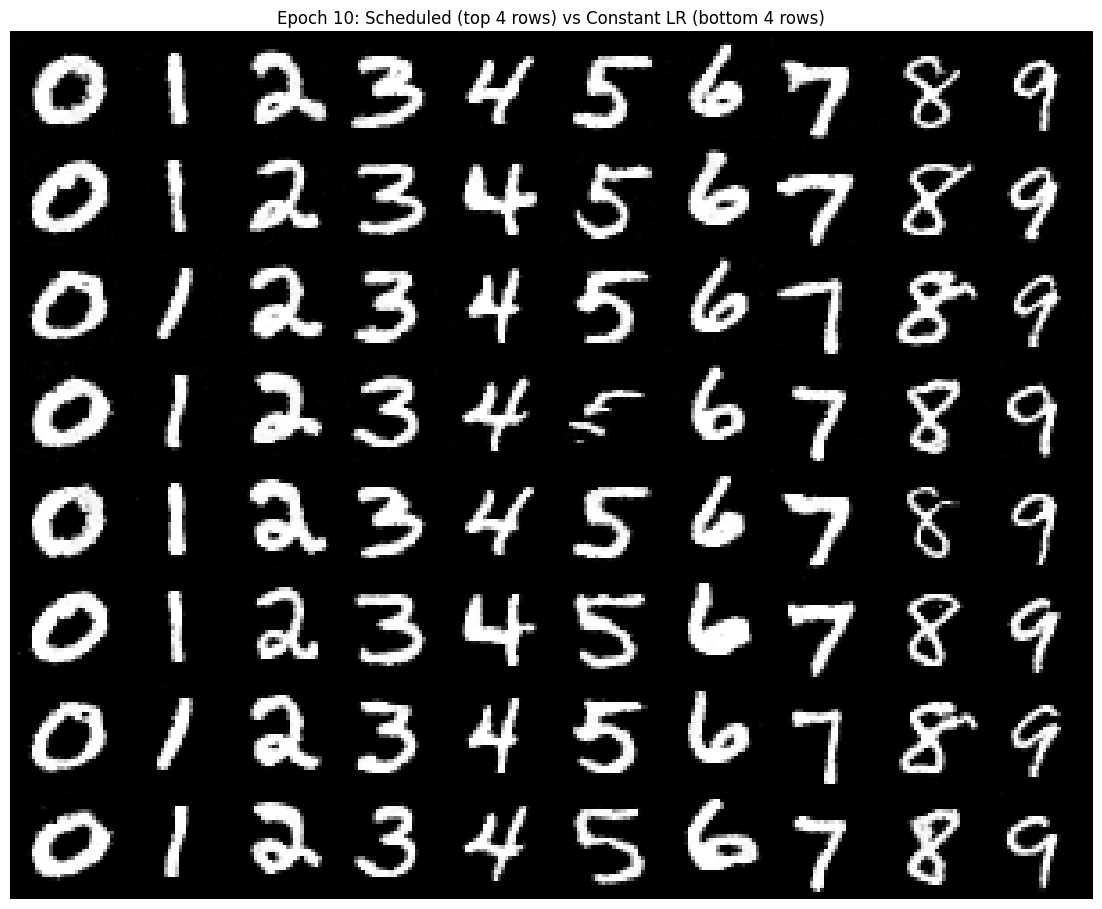

In [ ]:

# Compare scheduled vs no-scheduler generation

scheduled = results[("class_fm_scheduled", 10)]
no_scheduler = results[("class_fm_no_scheduler", 10)]

# Stack the two 4x10 grids vertically
comparison = torch.cat(
    [scheduled, no_scheduler],
    dim=0
)

show_grid(
    comparison,
    title=(
        "Epoch 10: Scheduled (top 4 rows) "
        "vs Constant LR (bottom 4 rows)"
    ),
    filename="part2_6_scheduler_visual_comparison.png",
    nrow=10
)

In [ ]:

from google.colab import drive
from pathlib import Path
import shutil

drive.mount('/content/drive')

# Current results location
source = Path(OUT).resolve()

# Permanent Google Drive folder
backup = Path(
    '/content/drive/MyDrive/CS180/Project3/PartB/results'
)
backup.mkdir(parents=True, exist_ok=True)

# Copy generated results and checkpoints
if source != backup:
    files_copied = 0
    for item in source.iterdir():
        if item.is_file():
            shutil.copy2(item, backup / item.name)
            files_copied += 1
    print(f"Copied {files_copied} files.")
else:
    print("Results are already saved in this Drive folder.")

print("\nBackup location:", backup)
print("\nSaved files:")
for item in sorted(backup.iterdir()):
    if item.is_file():
        print(item.name)


Mounted at /content/drive
Copied 37 files.

Backup location: /content/drive/MyDrive/CS180/Project3/PartB/results

Saved files:
class_fm_no_scheduler_epoch_1.pt
class_fm_no_scheduler_epoch_10.pt
class_fm_no_scheduler_epoch_10_samples.png
class_fm_no_scheduler_epoch_5.pt
class_fm_no_scheduler_latest.pt
class_fm_no_scheduler_training_loss.png
class_fm_scheduled_epoch_1.pt
class_fm_scheduled_epoch_10.pt
class_fm_scheduled_epoch_10_samples.png
class_fm_scheduled_epoch_1_samples.png
class_fm_scheduled_epoch_5.pt
class_fm_scheduled_epoch_5_samples.png
class_fm_scheduled_latest.pt
class_fm_scheduled_training_loss.png
class_fm_scheduler_comparison.png
denoiser_epoch_1.png
denoiser_epoch_1.pt
denoiser_epoch_5.png
denoiser_epoch_5.pt
part1_2_1_denoising_loss.png
part1_2_2_ood_testing.png
part1_2_3_pure_noise_loss.png
part1_2_noising.png
part2_2_time_conditioned_loss.png
part2_3_sampling_comparison.png
part2_6_scheduler_visual_comparison.png
pure_noise_epoch_1.png
pure_noise_epoch_1.pt
pure_noise_